In [ ]:
# Copyright 2026 B-Open
#
# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
#   http://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

# Introduction and Scope

The objective of this notebook is to provide evidence for the qualification step of the COP ARD Processors for Sentinel-1 data.

In particular, this notebook presents the Enhanced Spectral Diversity (ESD) co-registration accuracy analysis for test cases **TC-ST-PERF-003** and **TC-ST-PERF-004**, as defined in the Software Verification Plan (D15v1.1).

---

# TC-ST-PERF-003 and TC-ST-PERF-004: ESD Co-Registration Accuracy Analysis

## Input Products

The qualification dataset for TC-ST-PERF-003 and TC-ST-PERF-004 includes the following Sentinel-1 IW CSLC stacks over the Surat Basin (Ascending Geometry):

1. **TC-ST-PERF-003 (Model-Based / ETAD-only):**  
   `s3://bopen-sar/ARD-ROSE-L/SENTINEL/Surat/009/OUTPUT/TC-ST-PERF-003/CSLC`
2. **TC-ST-PERF-004 (Data-Driven / ETAD + ESD):**  
   `s3://bopen-sar/ARD-ROSE-L/SENTINEL/Surat/009/OUTPUT/TC-ST-PERF-004/CSLC`

---

### Test Case Specifications & ESD Quality Metrics

| Field | Description |
| :--- | :--- |
| **Test Case IDs** | **TC-ST-PERF-003** (Model-Based) & **TC-ST-PERF-004** (Data-Driven) |
| **Requirement(s)** | **TC-ST-PERF-003:** APP-PERF-001, APP-PERF-005<br>**TC-ST-PERF-004:** APP-PERF-001, APP-PERF-007 |
| **Objective** | To evaluate and verify the temporal azimuth co-registration accuracy of the CSLC products generated by the COP ARD processing chain using Enhanced Spectral Diversity (ESD).<br><br>• **TC-ST-PERF-003:** Evaluates the baseline residual azimuth shift using geometry and ETAD corrections (Model-Based).<br>• **TC-ST-PERF-004:** Verifies that the full processing chain (ETAD + ESD) achieves sub-percentage pixel alignment accuracy. |
| **Test Data** | CSLC temporal stacks generated from Sentinel-1 IW acquisition dates over the Surat Basin calibration site. |
| **Pre-conditions** | <ul><li>CSLC products generated for both test configurations across all dates.</li><li>Subswaths ($\text{IW1}$, $\text{IW2}$, $\text{IW3}$) properly split and organized into DataTrees.</li><li>Dask cluster enabled for parallelized burst concatenation and ESD estimation.</li></ul> |
| **Procedure** | <ul><li>Iterate through sequential acquisition date pairs for each test case (`003` and `004`).</li><li>Extract overlapping burst pairs for each subswath ($\text{IW1}$, $\text{IW2}$, $\text{IW3}$).</li><li>Execute ESD estimation to measure residual azimuth pixel shifts.</li><li>Compute the spatial mean ($\mu$) and standard deviation ($\sigma$) of the azimuth shifts across all burst overlaps for each acquisition date and subswath.</li><li>Plot the time series of azimuth shifts ($\mu \pm \sigma$) with temporal jittering for subswath separation and compare against the requirement thresholds.</li></ul> |
| **Pass Criteria** | **Co-registration Accuracy (Azimuth Shift):**<br><ul><li>**TC-ST-PERF-003:** The absolute mean azimuth shift shall remain within $\le \pm 2\%$ of a pixel ($\pm 0.020\text{ px}$).</li><li>**TC-ST-PERF-004:** The absolute mean azimuth shift shall remain within $\le \pm 0.5\%$ of a pixel ($\pm 0.005\text{ px}$).</li></ul> |

In [ ]:
import xarray as xr
import matplotlib.pyplot as plt
from collections import defaultdict
from cop_ard_app.computation import create_client, map
from cop_ard_app.io import read, write, glob
from cop_ard_app.esd import estimate
from cop_ard_app.utils import split_slc_datatrees

plt.rcParams["font.family"] = "serif"
cmap = plt.get_cmap("tab10")
colors = [cmap(i) for i in range(cmap.N)]
markers = ["s", "^", "v", "P", "*", "X", "d"]
ls = ["--", "-", "dotted", "-."]

In [ ]:
client = create_client("LOCAL", 8, 0)

In [2]:
cslc_path_003 = "s3://bopen-sar/ARD-ROSE-L/SENTINEL/Surat/009/OUTPUT/TC-ST-PERF-003/CSLC"
cslc_path_004 = "s3://bopen-sar/ARD-ROSE-L/SENTINEL/Surat/009/OUTPUT/TC-ST-PERF-004/CSLC"
reference_path = "s3://bopen-sar/ARD-ROSE-L/SENTINEL/Surat/009/REF_DB/reference_db_static"
esd_poly_degree = 0
esd_path = "/data/tmp/ESD"
multiburst = True
enable_dask = True

In [9]:
def read_burst(path_burst):
    name = path_burst[-9:]
    cslc = read(f"{path_burst}/measurements", consolidated=False).cslc.drop_attrs()
    return (name, cslc)


def concat(name, bursts):
    sw, id = name.split("_")
    n = f"iw{sw[1]}_{int(id)}"
    ref_burst = read(f"{reference_path}/bursts/{n}/reference/measurements", consolidated=False).slc
    attrs = ref_burst.attrs
    azimuth_m = ref_burst.azimuth_m.values
    slant_range_m = ref_burst.slant_range_m.values
    c = (
        xr.concat(bursts, dim="acquisition_id")
        .assign_coords({"azimuth_m": ("azimuth_time", azimuth_m), "slant_range_m": ("slant_range_time", slant_range_m)})
        .assign_attrs(attrs)
    ).sortby("acquisition_date")
    return (n, c)

In [ ]:
cslc_paths = {
    "003": cslc_path_003,
    "004": cslc_path_004,
}

bursts_dicts = {}

for case_id, cslc_path in cslc_paths.items():
    files = sorted(glob(f"{cslc_path}/cslc*"))
    acquisition_dates = sorted([k.split("cslcs_")[1].removesuffix(".zarr") for k in files])
    ref_path = files[0]
    for counter, sec_path in enumerate(files[1:]):
        print("=" * 50)

        ref_date = acquisition_dates[counter]
        sec_date = acquisition_dates[counter + 1]
        if ref_date not in ref_path:
            raise ValueError(f"Reference date {ref_date} not found in {ref_path}")
        if sec_date not in sec_path:
            raise ValueError(f"Secondary date {sec_date} not found in {sec_path}")
        print(f"Computing: {ref_date}  <--->  {sec_date}")

        bursts_dict = defaultdict(list)

        for f in [ref_path, sec_path]:
            bursts = glob(f"{f}/*CSL*")
            res = map(read_burst, bursts)
            for k, v in res:
                bursts_dict[k].append(v)

        args = [list(bursts_dict.keys()), list(bursts_dict.values())]
        res = map(concat, args, enable_dask=True)
        cslcs = xr.DataTree()
        for k, v in res:
            cslcs[f"bursts/{k}/coreg/measurements/cstack"] = v
            cslcs[f"bursts/{k}/orig"] = xr.Dataset()

        reference_id = next(iter(cslcs.bursts.values())).coreg.measurements.acquisition_id.values[0]

        ref_slcs, sec_slcs = split_slc_datatrees(
            slcs=cslcs,
            reference_id=reference_id,
            multiburst=multiburst,
        )
        esd_res = estimate(
            ref_slcs,
            sec_slcs,
            poly_degree=esd_poly_degree,
            enable_dask=enable_dask,
        ).assign_coords({"acquisition_date": sec_date})
        esd_res = write(esd_res, f"{esd_path}/{case_id}/esd_{sec_date}")
        ref_path = sec_path

In [ ]:
esd_003 = xr.concat(
    [read(k, as_type="xr.Dataset") for k in glob(f"{esd_path}/003/esd_20*")], dim="acquisition_id"
).sortby("acquisition_date")
esd_004 = xr.concat(
    [read(k, as_type="xr.Dataset") for k in glob(f"{esd_path}/004/esd_20*")], dim="acquisition_id"
).sortby("acquisition_date")

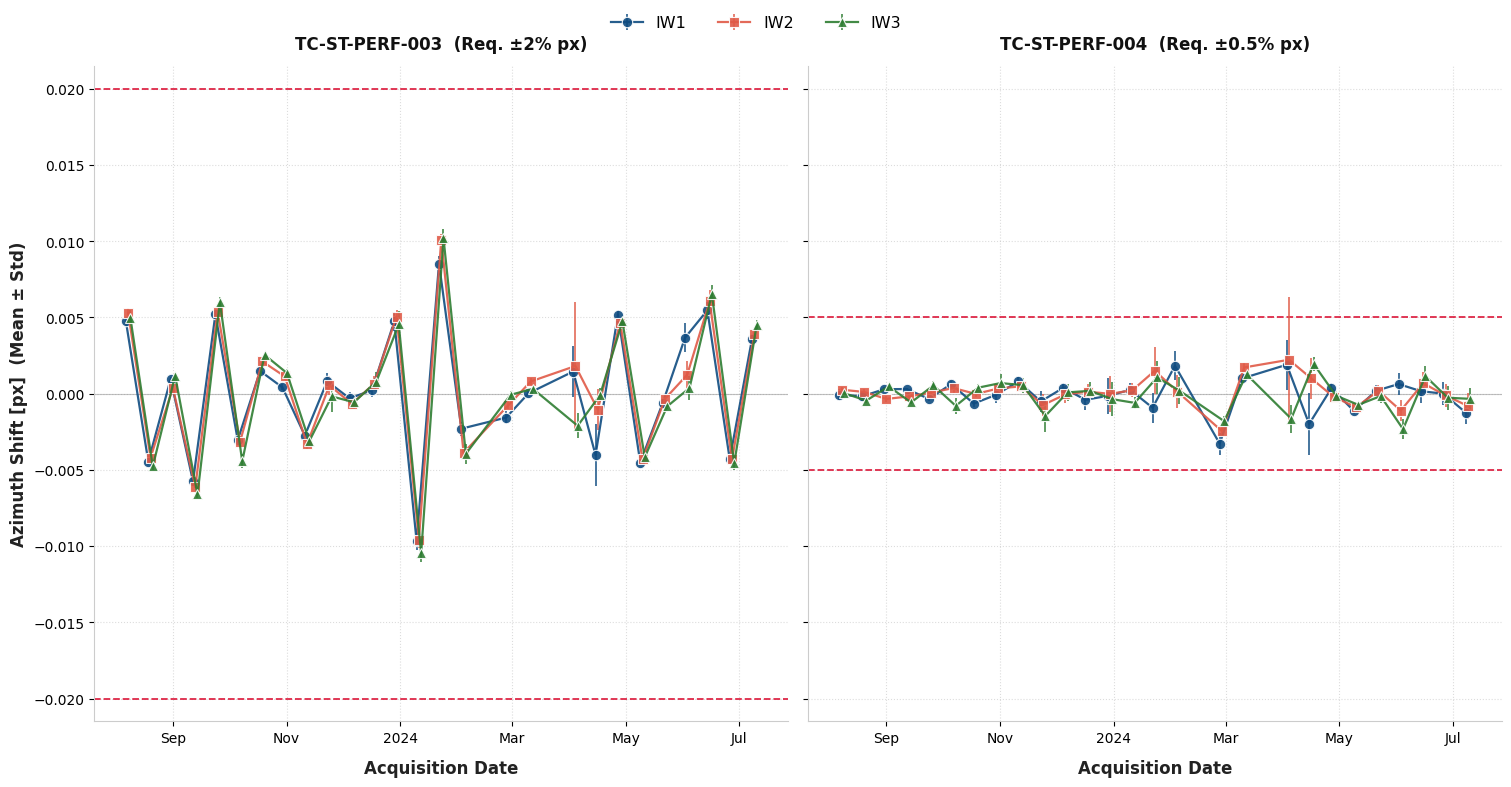

In [24]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Font ingranditi per una leggibilità perfetta
plt.rcParams.update(
    {
        "font.sans-serif": "DejaVu Sans",
        "font.size": 11,
        "axes.labelsize": 12,
        "axes.titlesize": 12,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
    }
)

datasets = [
    ("TC-ST-PERF-003", esd_003, 0.020, "±2% px"),
    ("TC-ST-PERF-004", esd_004, 0.005, "±0.5% px"),
]

colors = ["#0F4C81", "#E05A47", "#2E7D32"]
markers = ["o", "s", "^"]

time_offsets = [
    pd.Timedelta(days=-1.2),
    pd.Timedelta(days=0),
    pd.Timedelta(days=1.2),
]

# 2. Ingrandita la figura (15x7.5 pollici) per eliminare l'effetto schiacciato
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5), sharey=True, layout="constrained")

for col_idx, (title, esd, req_val, req_label) in enumerate(datasets):
    mean_shift = esd.mean_shift
    ax = axes[col_idx]

    ax.set_title(f"{title}  (Req. {req_label})", fontweight="bold", pad=12, color="#111111")
    ax.axhline(0, color="#888888", linestyle="-", linewidth=0.8, alpha=0.5)

    # Linee dei requisiti
    ax.axhline(req_val, color="#D90429", linestyle="--", linewidth=1.3, alpha=0.85)
    ax.axhline(-req_val, color="#D90429", linestyle="--", linewidth=1.3, alpha=0.85)

    for counter, subswath in enumerate(["iw1", "iw2", "iw3"]):
        mask = [e for e, id_val in enumerate(mean_shift.id.values) if subswath in id_val]
        data = mean_shift.isel(id=mask, drop=True)

        mean = data.mean(dim="id")
        std = data.std(dim="id", ddof=1) / np.sqrt(data.id.size)
        dates = pd.to_datetime(data.acquisition_date.values) + time_offsets[counter]

        # 3. Marcatori più grandi (ms=7.5) e linee più visibili (lw=1.6)
        ax.errorbar(
            dates,
            mean,
            yerr=std,
            fmt="-",
            lw=1.6,
            marker=markers[counter],
            ms=7.5,
            mec="white",
            mew=0.8,
            color=colors[counter],
            ecolor=colors[counter],
            elinewidth=1.2,
            capsize=0,
            alpha=0.9,
            label=subswath.upper(),
        )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#cccccc")
    ax.spines["bottom"].set_color("#cccccc")
    ax.grid(True, linestyle=":", alpha=0.5, color="#bbbbbb")

# Scala Y unica ben bilanciata
axes[0].set_ylim(-0.0215, 0.0215)

# Formattazione date
locator = mdates.AutoDateLocator(minticks=5, maxticks=8)
formatter = mdates.ConciseDateFormatter(locator)

for ax in axes:
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(formatter)
    ax.set_xlabel("Acquisition Date", fontweight="bold", labelpad=10, color="#222222")

axes[0].set_ylabel("Azimuth Shift [px]  (Mean ± Std)", fontweight="bold", color="#222222")

# Legenda con testo più grande
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.04),
    ncols=3,
    frameon=False,
    fontsize=11.5,
)

plt.show()